<a href="https://colab.research.google.com/github/feliciadominic14-create/Homework/blob/main/Felicia_Dominic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, PowerTransformer
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif

In [5]:
filepath='/content/adult_dataset (1).csv'
df = pd.read_csv(filepath)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [7]:
num_Colmns = df.select_dtypes(include=["number"]).columns
Cat_colmns = df.select_dtypes(include=["object"]).columns

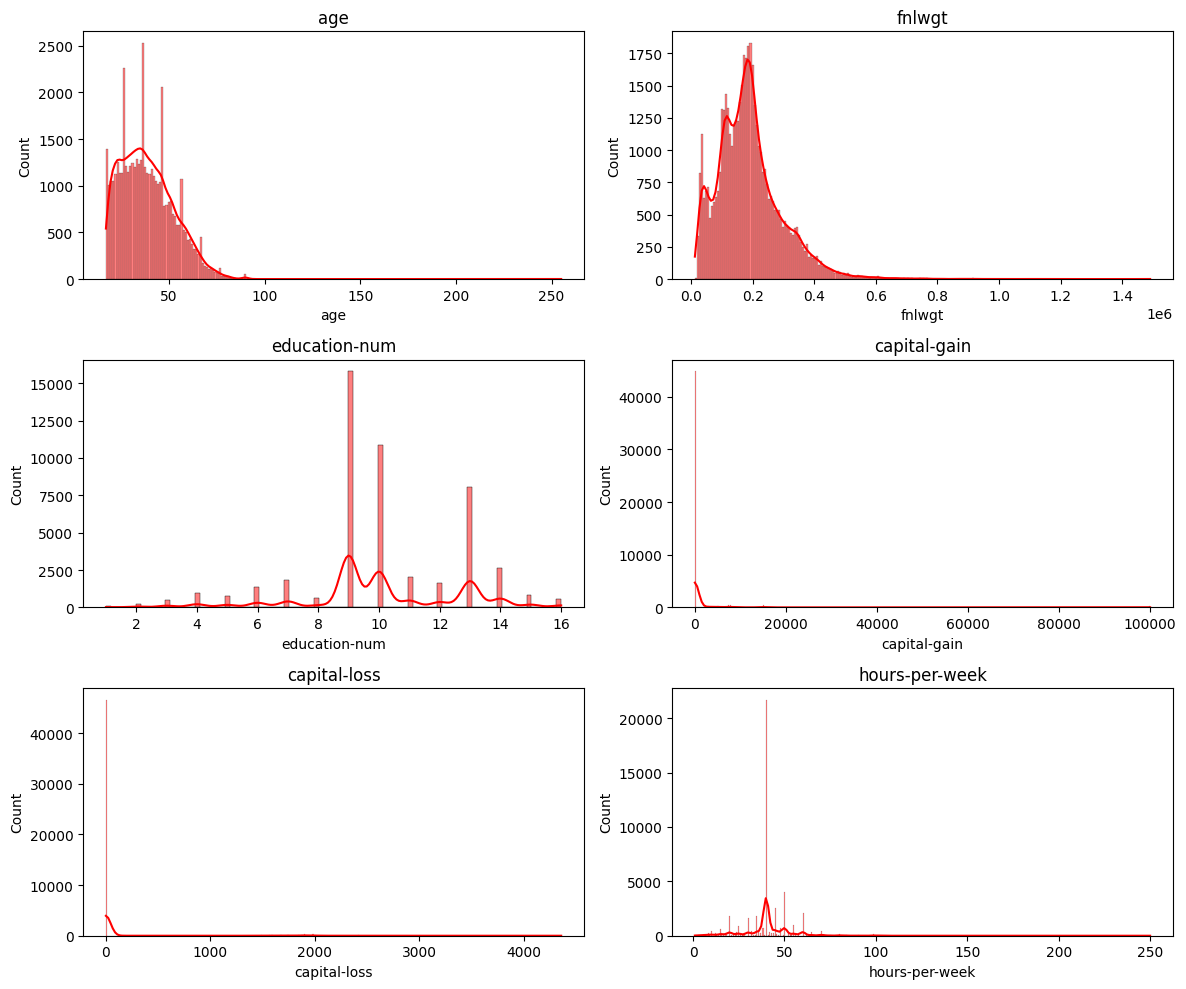

In [8]:
plt.figure(figsize=(12, 10))
for i, col in enumerate(num_Colmns, 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col], edgecolor="Black", color="Red", kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

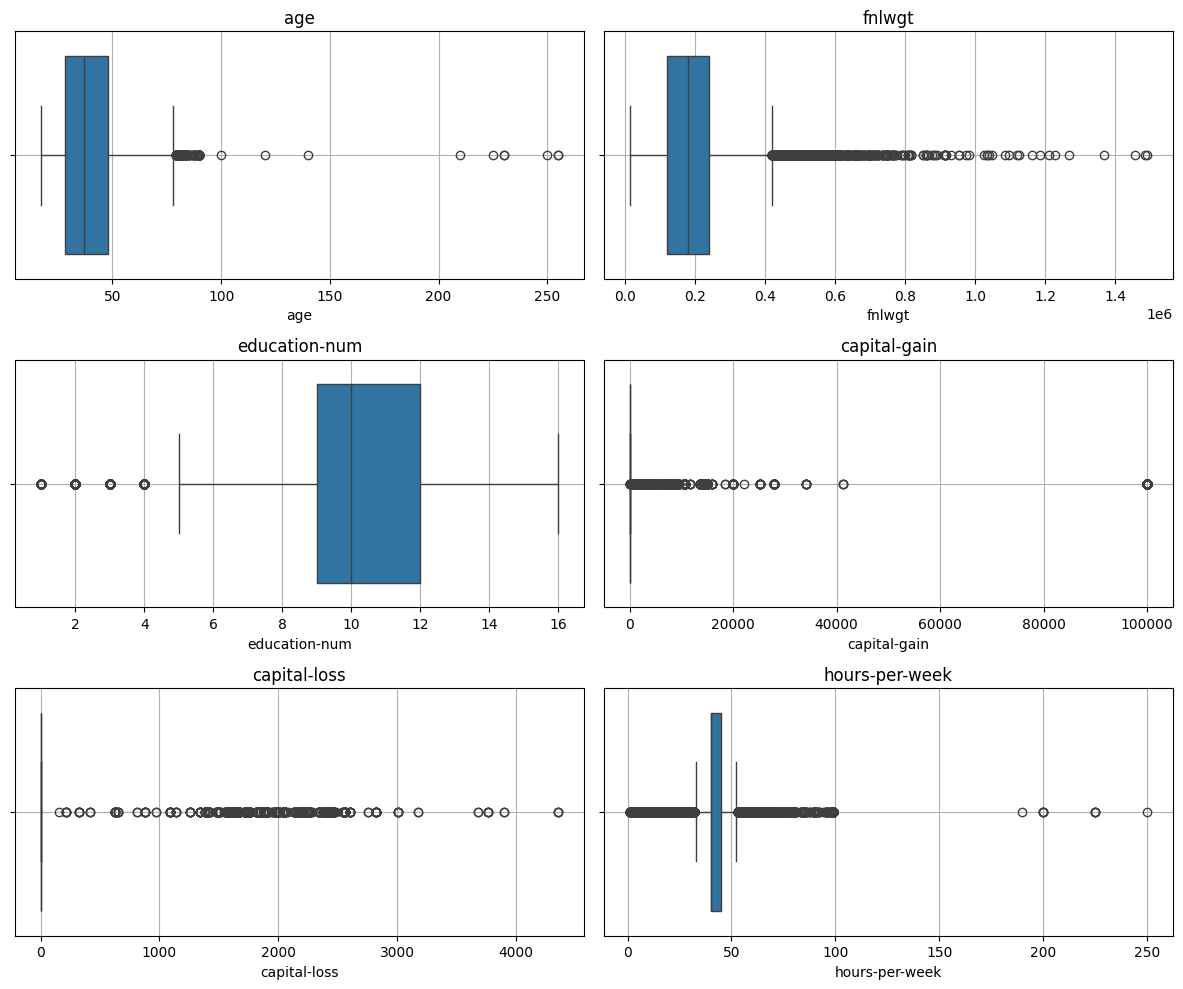

In [9]:
plt.figure(figsize=(12, 10))
for i, col in enumerate(num_Colmns, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=df[col].dropna())
    plt.title(col)
    plt.grid()
plt.tight_layout()
plt.show()

In [10]:
df['income'] = df['income'].str.replace('.', '', regex=False).str.strip().map({'<=50K': 0, '>50K': 1})

In [11]:
df.replace('?', np.nan, inplace=True)

In [12]:
df = df.drop_duplicates().reset_index(drop=True)

In [13]:
df = df[~((df['age'] > 100) | (df['hours-per-week'] > 168))].reset_index(drop=True)

In [14]:
df = df.drop(columns=['education', 'fnlwgt'])

In [15]:
X = df.drop(columns=['income'])
y = df['income']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [18]:
num_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
cat_cols = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

In [19]:
num_imputer = SimpleImputer(strategy='median')
X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

In [20]:
cat_imputer = SimpleImputer(strategy='constant', fill_value='Missing')
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

In [21]:
ohe = OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore', min_frequency=50)

In [22]:
X_train_ohe = pd.DataFrame(
    ohe.fit_transform(X_train[cat_cols]),
    columns=ohe.get_feature_names_out(cat_cols),
    index=X_train.index
)
X_test_ohe = pd.DataFrame(
    ohe.transform(X_test[cat_cols]),
    columns=ohe.get_feature_names_out(cat_cols),
    index=X_test.index
)

In [23]:
X_train_prep = pd.concat([X_train[num_cols], X_train_ohe], axis=1)
X_test_prep = pd.concat([X_test[num_cols], X_test_ohe], axis=1)

In [24]:
for col in ['capital-gain', 'capital-loss']:
    X_train_prep[col] = np.log1p(X_train_prep[col])
    X_test_prep[col] = np.log1p(X_test_prep[col])

In [25]:
vt = VarianceThreshold(threshold=0.01)
vt.fit(X_train_prep)

VarianceThreshold(threshold=0.01)

In [26]:
X_train_vt = X_train_prep.loc[:, vt.get_support()].copy()
X_test_vt = X_test_prep.loc[:, vt.get_support()].copy()

In [27]:
corr_with_y = pd.concat([X_train_vt[num_cols], y_train.rename('income')], axis=1).corr()['income'].sort_values(ascending=False)
mi_scores = pd.Series(
    mutual_info_classif(X_train_vt, y_train, random_state=42),
    index=X_train_vt.columns
).sort_values(ascending=False)
print("Correlation with income:\n", corr_with_y)
print("\nTop 10 Mutual Information features:\n", mi_scores.head(10))

Correlation with income:
 income            1.000000
education-num     0.333126
capital-gain      0.283921
hours-per-week    0.224529
age               0.223579
capital-loss      0.135285
Name: income, dtype: float64

Top 10 Mutual Information features:
 marital-status_Married-civ-spouse    0.108202
relationship_Husband                 0.086004
capital-gain                         0.081231
marital-status_Never-married         0.062768
education-num                        0.061962
age                                  0.061590
hours-per-week                       0.038991
relationship_Own-child               0.038818
capital-loss                         0.036580
sex_Male                             0.029724
dtype: float64


In [28]:
std_scaler = StandardScaler()
mm_scaler = MinMaxScaler()

In [29]:
X_train_std = X_train_vt.copy()
X_test_std = X_test_vt.copy()
X_train_std[num_cols] = std_scaler.fit_transform(X_train_vt[num_cols])
X_test_std[num_cols] = std_scaler.transform(X_test_vt[num_cols])

In [30]:
X_train_mm = X_train_vt.copy()
X_test_mm = X_test_vt.copy()
X_train_mm[num_cols] = mm_scaler.fit_transform(X_train_vt[num_cols])
X_test_mm[num_cols] = mm_scaler.transform(X_test_vt[num_cols])